# FD001: dự báo Health Index ở đoạn cuối vòng đời

**Học viên:** Phan Nguyễn Mai Phương — **MSHV:** 25002711

Notebook 03 dự đoán số cycle còn lại. Ở đây, bài toán là **dự báo đường Health Index**
(chỉ số tổng hợp từ sensor) trong 30% cuối của một chuỗi đã quan sát 70% đầu.

Notebook dựng lại Health Index từ raw train, fit ARIMA cho 10 động cơ và so sánh với hai baseline.
Theo dõi **động cơ train 39** để thấy điểm cắt, đoạn dự báo và sai số cụ thể.
Kết quả mới được lưu ở `outputs/notebook04/run-*/`; test không được đọc.

Các số nêu trong lời giải thích là mốc đối chiếu từ pipeline đã bàn giao. Dự báo Health Index
không được dùng làm RUL hay đưa vào lịch bảo trì.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src/cmapss").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from IPython.display import display
from cmapss.presentation import COLORS, apply_plot_style, style_figure
apply_plot_style()


## 1. Tách động cơ dùng để học Health Index khỏi động cơ dự báo

Chọn 10 động cơ theo fold và chiều dài vòng đời, không chọn theo sai số dự báo.
**90 động cơ còn lại** dùng để fit StandardScaler và PCA. Toàn bộ lịch sử của 10 động cơ được chọn
chỉ được transform bằng các tham số đó, để đoạn holdout không tham gia học Health Index.

In [2]:
from cmapss.data.readers import read_observations
from cmapss.timeseries.health_index import fit_health_index, select_validation_engines

%matplotlib inline

RAW_PATH = ROOT / "data/raw/train_FD001.txt"
FOLD_PATH = ROOT / "outputs/modeling/tables/fold_assignments.csv"
train = read_observations(RAW_PATH, split="train")
folds = pd.read_csv(FOLD_PATH)
selected = select_validation_engines(train, folds, n_engines=10)
fit_ids = sorted(set(train.engine_id) - set(selected.engine_id))
assert len(fit_ids) == 90 and set(fit_ids).isdisjoint(selected.engine_id)
selected[["engine_id", "fold", "n_cycles"]]

,engine_id,fold,n_cycles
0,39,1,128
1,69,1,362
2,24,2,147
3,92,2,341
4,91,3,135
5,96,3,336
6,70,4,137
7,67,4,313
8,57,5,137
9,83,5,293


Health Index gồm ba phép biến đổi: chuẩn hóa 21 sensor, chiếu lên **một thành phần PCA (PC1)**,
rồi chọn dấu và chuẩn hóa PC1 bằng các tham số học từ 90 động cơ. Dấu được chọn để chỉ số
có chiều giảm theo cycle trên phần fit. Một giá trị HI là tổ hợp của các sensor,
với đơn vị sau cùng là độ lệch chuẩn của PC1 trên phần fit.

In [3]:
fitted_hi = fit_health_index(train, fit_engine_ids=fit_ids)
health_index = fitted_hi.health_index
history = health_index.query("engine_id == 39").sort_values("cycle")
cut = int(np.floor(len(history) * 0.7))
assert 39 not in fitted_hi.fit_engine_ids
history.loc[history.cycle.isin([1, cut, cut + 1, len(history)]),
            ["engine_id", "cycle", "health_index"]]

,engine_id,cycle,health_index
7510,39,1,0.023948
7598,39,89,-0.687793
7599,39,90,-1.000526
7637,39,128,-2.649415


ARIMA chỉ nhìn đoạn đầu kết thúc ở `cut`; phần bên phải được giữ để kiểm tra dự báo.
Hình này dùng Health Index thật ở cả hai đoạn để người đọc nhìn được điều gì xảy ra sau điểm cắt.

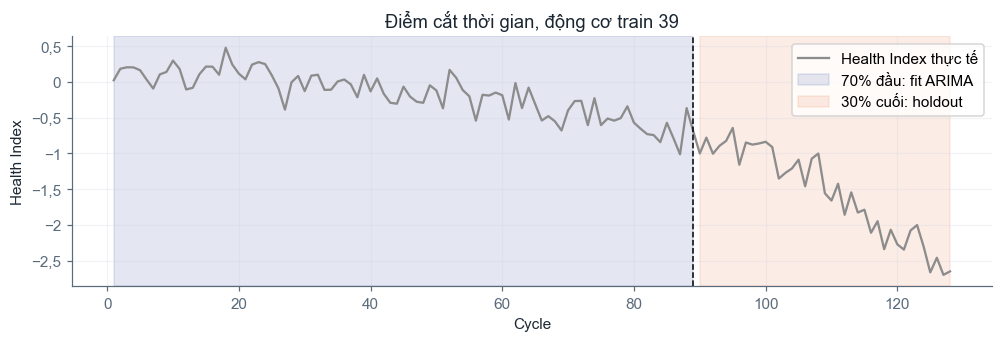

In [4]:
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.plot(history.cycle, history.health_index, color="0.55", label="Health Index thực tế")
ax.axvspan(1, cut, color=COLORS["blue"], alpha=0.12, label="70% đầu: fit ARIMA")
ax.axvspan(cut + 1, len(history), color=COLORS["orange"], alpha=0.12, label="30% cuối: holdout")
ax.axvline(cut, color="black", linestyle="--", linewidth=1)
ax.set(title="Điểm cắt thời gian, động cơ train 39", xlabel="Cycle", ylabel="Health Index")
ax.legend()
style_figure(fig)
display(fig)
plt.close(fig)

Trước khi fit ARIMA, kiểm tra xu hướng của Health Index trên cả 100 động cơ.
Spearman rho gần −1 biểu thị liên hệ giảm gần như đơn điệu giữa cycle và chỉ số.

In [5]:
from cmapss.eda import engine_cycle_correlations

rho = engine_cycle_correlations(health_index, "health_index")
rho.describe().round(4)

count    100.0000
mean      -0.9249
std        0.0254
min       -0.9589
25%       -0.9421
50%       -0.9315
75%       -0.9167
max       -0.8356
dtype: float64

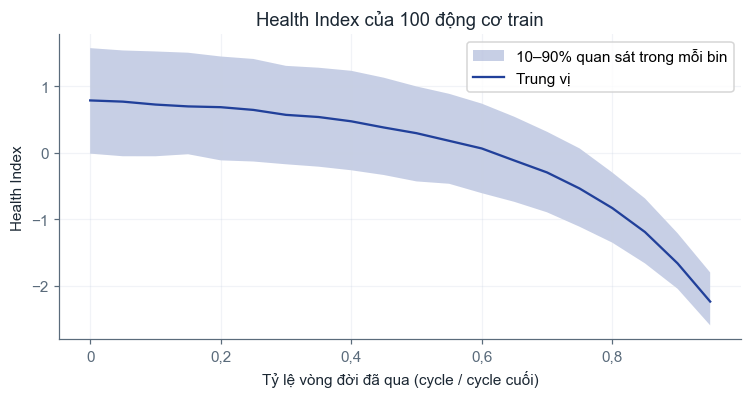

In [6]:
life = health_index.groupby("engine_id")["cycle"].transform("max")
hi = health_index.assign(life_fraction=health_index["cycle"] / life)
hi["bin"] = (hi["life_fraction"] * 20).clip(upper=19.999).astype(int) / 20
band = hi.groupby("bin")["health_index"].quantile([0.1, 0.5, 0.9]).unstack()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(band.index, band[0.1], band[0.9], alpha=0.25, label="10–90% quan sát trong mỗi bin")
ax.plot(band.index, band[0.5], label="Trung vị")
ax.set(xlabel="Tỷ lệ vòng đời đã qua (cycle / cycle cuối)", ylabel="Health Index", title="Health Index của 100 động cơ train")
ax.legend()
style_figure(fig)
display(fig)
plt.close(fig)

Cả 100 động cơ có rho âm, từ khoảng −0,96 đến −0,84, trung vị −0,93.
Đường trung vị giảm chậm trong khoảng 60% đầu rồi giảm nhanh hơn về cuối.
Dải trên hình là các phân vị của observations trong từng bin tỷ lệ vòng đời.

Cycle cuối chỉ được dùng để căn chỉnh hình mô tả này; ARIMA dự báo theo cycle gốc.
Nếu tốc độ giảm ở holdout nhanh hơn phần fit, dự báo có thể giảm quá chậm.

## 2. Fit ARIMA và dự báo phần giữ riêng

ARIMA(p, d, q) kết hợp p độ trễ tự hồi quy, sai phân bậc d và q độ trễ sai số.
Với mỗi động cơ, project thử p, q từ 0 đến 2 và d trong {0, 1}, chọn AIC thấp nhất **chỉ trên 70% đầu**.
Sau đó dự báo toàn bộ holdout từ cùng một điểm cắt, kèm khoảng dự đoán 95%.

MAE và RMSE đo sai số trên thang Health Index. Coverage là tỷ lệ điểm holdout nằm trong khoảng dự đoán;
mức 95% là mức danh nghĩa cần đối chiếu với tỷ lệ thực đo.

In [7]:
from cmapss.timeseries.arima import fit_engine_arima

forecast_rows, metric_rows, diagnostic_rows = [], [], []
for row in selected.itertuples(index=False):
    series = health_index.loc[health_index.engine_id.eq(row.engine_id), ["cycle", "health_index"]]
    forecast, scores, diagnostic = fit_engine_arima(
        series, split="train", engine_id=row.engine_id, fold=row.fold, train_fraction=0.7,
    )
    forecast_rows.append(forecast)
    metric_rows.append(scores)
    diagnostic_rows.append(diagnostic)
forecasts = pd.concat(forecast_rows, ignore_index=True)
forecast_metrics = pd.DataFrame(metric_rows)
diagnostics = pd.DataFrame(diagnostic_rows)

In [8]:
arima = forecast_metrics.set_index("engine_id").sort_index()
arima[["order", "n_train", "n_holdout", "mae", "rmse", "coverage_95"]].round(3)

,order,n_train,n_holdout,mae,rmse,coverage_95
engine_id,,,,,,
24,"(1, 0, 1)",102,45,0.157,0.190,0.956
39,"(0, 1, 1)",89,39,0.886,1.079,0.359
57,"(1, 0, 2)",95,42,0.435,0.523,0.500
67,"(2, 0, 1)",219,94,0.161,0.202,0.936
69,"(1, 0, 1)",253,109,0.459,0.564,0.505
70,"(2, 1, 2)",95,42,1.037,1.220,0.214
83,"(1, 0, 1)",205,88,0.171,0.217,0.875
91,"(1, 0, 1)",94,41,0.490,0.642,0.488
92,"(1, 0, 1)",238,103,0.163,0.207,0.893


Xem động cơ train 39 và động cơ train 24 để đọc hai trường hợp khác nhau trong bảng vừa tính.
Đường dự báo và khoảng đỏ bắt đầu sau điểm cắt; phần màu xám là Health Index thực tế.

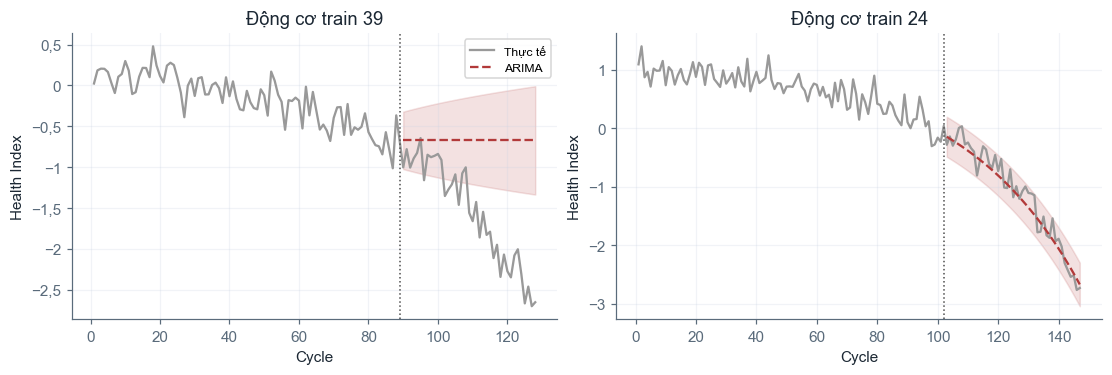

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
for ax, engine_id in zip(axes, [39, 24]):
    h = health_index.query("engine_id == @engine_id")
    fc = forecasts.query("engine_id == @engine_id")
    ax.plot(h.cycle, h.health_index, color="0.6", label="Thực tế")
    ax.plot(fc.cycle, fc.health_index_pred, color=COLORS["red"], linestyle="--", label="ARIMA")
    ax.fill_between(fc.cycle, fc.lower_95, fc.upper_95, color=COLORS["red"], alpha=0.15)
    ax.axvline(fc.cycle.min() - 1, color="0.3", linestyle=":", linewidth=1)
    ax.set(title=f"Động cơ train {engine_id}", xlabel="Cycle", ylabel="Health Index")
axes[0].legend(fontsize=8)
style_figure(fig)
display(fig)
plt.close(fig)

Ở động cơ 39, đường dự báo ARIMA gần như đi ngang, còn Health Index thực tế giảm nhanh ở cuối chuỗi.
Phần lớn điểm holdout vì vậy nằm ngoài khoảng dự đoán. Độ dốc cuối đời lớn hơn độ dốc trong đoạn fit,
phù hợp với xu hướng đã thấy ở mục 1.

In [10]:
arima[["mae", "rmse", "coverage_95"]].mean().round(3)

mae            0.411
rmse           0.503
coverage_95    0.670
dtype: float64

Năm động cơ 24, 67, 83, 92 và 96 có MAE khoảng 0,15–0,17, chưa tới 0,2 độ lệch chuẩn của Health Index,
và coverage 0,88–0,97. Năm động cơ còn lại có MAE từ 0,43 trở lên.
Sai số lớn nhất ở động cơ 70 (MAE 1,04, coverage 0,21) và 39 (MAE 0,89, coverage 0,36).

Coverage trung bình là 0,67, thấp hơn mức danh nghĩa 0,95.
Khoảng dự đoán của ARIMA quá hẹp trên các chuỗi này.

## 3. ARIMA có hơn hai cách dự báo đơn giản không?

Giữ nguyên điểm cắt của từng động cơ. `last_value` lặp lại giá trị cuối phần fit;
`drift` kéo dài đường thẳng nối điểm đầu và điểm cuối phần fit.
Cả hai dự báo toàn bộ holdout mà không đọc giá trị thật ở giữa.

In [11]:
from cmapss.timeseries.baselines import evaluate_forecast_baselines

baseline_rows = []
for row in selected.itertuples(index=False):
    values = health_index.loc[health_index.engine_id.eq(row.engine_id), "health_index"].to_numpy()
    n_train = int(arima.loc[row.engine_id, "n_train"])
    for name, scores in evaluate_forecast_baselines(values[:n_train], values[n_train:]).items():
        baseline_rows.append({"split": "train", "engine_id": row.engine_id,
                              "fold": row.fold, "baseline_name": name, **scores})
baseline_metrics = pd.DataFrame(baseline_rows)
comparison = baseline_metrics.pivot(index="engine_id", columns="baseline_name", values="mae")
comparison["arima"] = arima.mae
comparison["arima_best"] = comparison.arima < comparison[["last_value", "drift"]].min(axis=1)
comparison.round(4)

baseline_name,drift,last_value,arima,arima_best
engine_id,,,,
24,0.9198,1.1567,0.1572,True
39,0.7108,0.8701,0.8860,False
57,1.5685,1.6304,0.4346,True
67,0.4567,0.7095,0.1607,True
69,0.5023,0.7813,0.4585,True
70,0.7990,0.9586,1.0372,False
83,1.0064,1.2305,0.1708,True
91,0.3286,0.5289,0.4900,False
92,0.5105,0.6991,0.1631,True


In [12]:
print("ARIMA có MAE thấp nhất ở", comparison["arima_best"].sum(), "/", len(comparison), "động cơ")
comparison[["last_value", "drift", "arima"]].mean().round(3)

ARIMA có MAE thấp nhất ở 7 / 10 động cơ


baseline_name
last_value    0.948
drift         0.747
arima         0.411
dtype: float64

ARIMA có MAE thấp nhất ở 7/10 động cơ. MAE trung bình là 0,41, so với 0,75 của `drift`
và 0,95 của `last_value`, giảm khoảng 45% so với baseline tốt hơn.

`last_value` có sai số lớn nhất do giữ nguyên giá trị cuối trong khi Health Index tiếp tục giảm.
Ở ba động cơ 39, 70 và 91, `drift` có MAE thấp hơn ARIMA: xu hướng tuyến tính đơn giản
phù hợp với đoạn cuối của các chuỗi này hơn.

## 4. Mô hình hội tụ có nghĩa là đã mô tả đủ chuỗi chưa?

ADF kiểm tra giả thuyết có unit root. P-value lớn nghĩa là chưa bác bỏ giả thuyết đó,
không tự nó chứng minh một xu hướng cụ thể. Ljung–Box kiểm tra tự tương quan còn lại trong residual;
p-value dưới 0,05 cho thấy còn cấu trúc phụ thuộc chưa được mô tả hết.

In [13]:
diag = diagnostics.set_index("engine_id").sort_index()[["order", "adf_pvalue", "ljung_box_pvalue", "fit_converged"]]
diag["autocorrelated_5pct"] = diag["ljung_box_pvalue"] < 0.05
diag

,order,adf_pvalue,ljung_box_pvalue,fit_converged,autocorrelated_5pct
engine_id,,,,,
24,"(1, 0, 1)",0.999032,0.095632,True,False
39,"(0, 1, 1)",0.860584,0.814431,True,False
57,"(1, 0, 2)",0.996572,0.511181,True,False
67,"(2, 0, 1)",0.983626,0.749335,True,False
69,"(1, 0, 1)",0.991744,0.031312,True,True
70,"(2, 1, 2)",0.981081,0.026869,True,True
83,"(1, 0, 1)",0.998544,0.433111,True,False
91,"(1, 0, 1)",0.996762,0.999993,True,False
92,"(1, 0, 1)",0.998863,0.438555,True,False


ADF p-value của cả 10 chuỗi đều trên 0,86, nên kiểm định chưa cho thấy tính dừng,
phù hợp với xu hướng giảm đã quan sát. Tất cả mô hình đều hội tụ.
Residual của động cơ 69 (p = 0,031) và 70 (p = 0,027) còn tự tương quan ở mức 5%.
Động cơ 70 cũng có sai số dự báo lớn nhất.

## 5. Lưu mô hình và kết quả vừa tính

Dùng writer của project để lưu scaler, PCA, tham số chuẩn hóa, danh sách 10 động cơ,
dự báo, bảng sai số và diagnostics. Raw và kết quả timeseries đã bàn giao được giữ nguyên.

In [14]:
import tempfile
import hashlib
from cmapss.timeseries.pipeline import TimeseriesConfig, TimeseriesResult, write_timeseries_artifacts

output_root = ROOT / "outputs/notebook04"
output_root.mkdir(parents=True, exist_ok=True)
OUTPUT = Path(tempfile.mkdtemp(prefix="run-", dir=output_root))
result = TimeseriesResult(
    config=TimeseriesConfig(), health_index_result=fitted_hi, selected_engines=selected,
    forecasts=forecasts, forecast_metrics=forecast_metrics, baseline_metrics=baseline_metrics,
    diagnostics=diagnostics,
    input_sha256={p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in (RAW_PATH, FOLD_PATH)},
)
run_info = write_timeseries_artifacts(result, OUTPUT)
print(f"Kết quả lần chạy: {OUTPUT.relative_to(ROOT)}")

Kết quả lần chạy: outputs\notebook04\run-j_pf7x7e


In [15]:
assert len(arima) == 10 and arima.fit_converged.all()
assert len(health_index) == 20631
assert forecasts.groupby("engine_id").size().eq(arima.n_holdout).all()
assert not set(selected.engine_id).intersection(fitted_hi.fit_engine_ids)

Health Index thể hiện xu hướng giảm trên FD001, nhưng dự báo đoạn cuối vẫn khó khi tốc độ suy giảm thay đổi.
Trong kết quả đối chiếu, ARIMA có MAE thấp hơn cả hai baseline ở 7/10 động cơ,
còn coverage trung bình khoảng 0,67, thấp hơn mức danh nghĩa 0,95.

Các kết quả trên đánh giá dự báo Health Index. Chúng chưa xác định được còn bao nhiêu cycle đến khi hỏng;
lịch bảo trì ở notebook 06 dùng mô hình RUL và một quy tắc bất thường riêng.